#Ejemplo de TP - Ingeniería de Software

Dado el dataset Rice que contiene información de dos tipos de arroces (en archivo adjunto Citation_Request.txt se lo describe) , el cual se comparte en el siguiente link (también pueden encontrar archivo csv. adjunto):

https://docs.google.com/spreadsheets/d/e/2PACX-1vR2JTCQKzRmjSJBUvu7OOrcBceJcdVbyU1NMdzbThKKcEgiJQ55PH1AfpzQGvbAV1Om6uz-PsOrgn5i/pub?gid=521645460&single=true&output=csv


# FASE 1 – Comprensión del Negocio / Business Understanding
## 1. Problema de negocio

El problema de negocio seleccionado consiste en la clasificación de variedades de arroz a partir de características físicas y morfológicas del grano, utilizando técnicas de análisis de datos y aprendizaje automático. En particular, se trabajará con el dataset de las variedades de arroz Cammeo y Osmancik, el cual contiene variables numéricas que describen propiedades geométricas de los granos de arroz, tales como área, perímetro, longitud del eje mayor, eje menor, excentricidad, entre otras.

Este problema es relevante en la industria alimentaria y agroindustrial, ya que la correcta clasificación de variedades de arroz permite:

*Mejorar los procesos de control de calidad.
*Automatizar la clasificación del producto.
*Evitar fraudes o mezclas de variedades.
*Mejorar la eficiencia en plantas de procesamiento.
*Determinar precios según la calidad o variedad del producto.

Actualmente, muchos procesos de clasificación se realizan de manera manual o mediante métodos mecánicos que no siempre son precisos, por lo que el uso de modelos de aprendizaje automático puede mejorar significativamente la precisión y reducir costos operativos.

## 2. Objetivo del análisis
###Objetivo general

Desarrollar un modelo de análisis de datos que permita clasificar granos de arroz en las variedades Cammeo y Osmancik a partir de sus características físicas, utilizando técnicas de análisis exploratorio de datos y modelos de aprendizaje automático, con el fin de mejorar la toma de decisiones en procesos de control de calidad y clasificación en la industria arrocera.

### Objetivos específicos
* Analizar y comprender las variables del dataset mediante análisis exploratorio de datos (EDA).
* Identificar qué variables presentan mayor capacidad para diferenciar las variedades de arroz.
* Preparar los datos para su utilización en modelos de aprendizaje automático.
* Entrenar un modelo de clasificación que permita distinguir entre arroz Cammeo y Osmancik.
* Evaluar el rendimiento del modelo utilizando métricas de clasificación.
* Analizar la importancia de las variables en la clasificación.
* Proponer posibles aplicaciones del modelo en un contexto real de negocio.

Estos objetivos permiten organizar el trabajo en etapas, desde la comprensión de los datos hasta la construcción y evaluación del modelo.

## 3. Stakeholders del negocio

Los principales stakeholders involucrados en este problema de negocio son:

* Productores agrícolas: interesados en la correcta identificación y clasificación de la variedad de arroz producida.
* Plantas de procesamiento de arroz: encargadas de clasificar, procesar y empaquetar el arroz.
* Empresas comercializadoras: venden el arroz según su variedad y calidad.
* Área de control de calidad: encargada de verificar que el producto corresponda a la variedad declarada.
* Consumidores finales: reciben el producto final y esperan calidad y uniformidad.
* Gerencia / Dirección de la empresa: encargada de la toma de decisiones estratégicas y de inversión en tecnología.
* Ingenieros de procesos / Ingenieros industriales: responsables de mejorar la eficiencia del proceso productivo.
* Equipo de Ciencia de Datos: encargado de desarrollar el modelo de clasificación.
## 4. Impacto de la solución en el negocio

La implementación de un sistema de clasificación automática basado en datos y aprendizaje automático puede generar distintos impactos según el stakeholder:

### Productores agrícolas

La correcta clasificación del arroz permite garantizar la pureza de la variedad, lo que puede impactar en el precio del producto y en la confianza del mercado.

### Plantas de procesamiento

Un sistema automatizado de clasificación permite:

* Reducir costos operativos.
* Aumentar la velocidad de clasificación.
* Reducir errores humanos.
* Mejorar la eficiencia del proceso.
### Empresas comercializadoras

Permite asegurar que el producto vendido corresponde a la variedad indicada, evitando problemas de calidad o reclamos de clientes.

### Área de control de calidad

El modelo puede utilizarse como una herramienta de apoyo para detectar errores de clasificación o mezclas de variedades.

### Gerencia / Dirección

Desde el punto de vista estratégico, la implementación de modelos de machine learning puede:

* Reducir costos.
* Mejorar la calidad del producto.
* Incorporar tecnología e innovación.
* Generar ventajas competitivas.
### Ingenieros de procesos

Permite optimizar procesos industriales mediante sistemas automáticos de clasificación basados en visión artificial y machine learning.

### Equipo de Ciencia de Datos

Representa un caso práctico de aplicación de modelos de clasificación, donde se puede medir el desempeño del modelo y su aplicabilidad en un problema real.

In [ ]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# from google.colab import files
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree


# FASE 2 – Comprensión y Exploración de los Datos (EDA)
## 1. Comprensión de los datos

En esta fase se realiza la comprensión del conjunto de datos que será utilizado para el análisis. El dataset utilizado corresponde a las variedades de arroz Cammeo y Osmancik, y contiene variables numéricas que describen características geométricas de los granos de arroz obtenidas mediante procesamiento de imágenes.

Cada registro del dataset representa un grano de arroz y cada columna representa una característica medida del mismo. Entre las variables presentes en el dataset se encuentran:

* Área
* Perímetro
* Longitud del eje mayor
* Longitud del eje menor
* Excentricidad
* Convex Area
* Extent
* Solidez
* Roundness
* Aspect Ratio
* Clase (Cammeo u Osmancik)

La variable Clase corresponde a la variable objetivo, ya que es la variable que se desea predecir mediante el modelo de clasificación.

El objetivo de esta fase es entender la estructura de los datos, identificar el tipo de variables, detectar valores faltantes, analizar la distribución de las variables y estudiar la relación entre ellas.

## 2. Análisis exploratorio de los datos (EDA)

El Análisis Exploratorio de Datos (EDA) permite obtener una primera comprensión del comportamiento de las variables y su relación con la variable objetivo. Esta etapa es fundamental antes de construir modelos de machine learning, ya que permite detectar problemas en los datos y entender qué variables pueden tener mayor poder explicativo.

### 2.1 Análisis de la estructura del dataset

En primer lugar, se analiza:

* Cantidad de filas (observaciones)
* Cantidad de columnas (variables)
* Tipos de datos de cada variable
* Identificación de la variable objetivo
* Identificación de variables numéricas y categóricas

Este análisis permite entender la dimensionalidad del problema y el tipo de modelo que se deberá utilizar posteriormente.

### 2.2 Análisis estadístico descriptivo

Se realiza un análisis estadístico descriptivo de las variables numéricas, calculando:

* Media
* Mediana
* Desvío estándar
* Valor mínimo
* Valor máximo
* Cuartiles (Q1, Q2, Q3)

Este análisis permite entender la dispersión de los datos, detectar posibles outliers y analizar si las variables presentan comportamientos muy diferentes entre sí.

### 2.3 Análisis de valores faltantes

En esta etapa se verifica la existencia de valores faltantes en el dataset. La presencia de valores nulos puede afectar el rendimiento de los modelos de machine learning, por lo que es importante detectarlos y definir una estrategia para tratarlos (eliminación de registros, imputación, etc.).

En caso de que el dataset no presente valores faltantes, esto representa una ventaja, ya que no será necesario realizar procesos de imputación.

### 2.4 Análisis de la distribución de las variables

Se analizan las distribuciones de las variables numéricas mediante histogramas y diagramas de caja (boxplots). Este análisis permite:

* Detectar outliers.
* Analizar la dispersión de los datos.
* Identificar si las variables presentan distribución normal o sesgada.
* Comparar la distribución de las variables entre las clases Cammeo y Osmancik.

Este punto es muy importante, ya que si las variables presentan diferencias significativas entre las clases, entonces serán buenas variables predictoras para el modelo de clasificación.

### 2.5 Análisis de correlación entre variables

Se construye una matriz de correlación para analizar la relación entre las variables numéricas. La correlación permite identificar:

* Variables altamente correlacionadas entre sí.
* Posibles problemas de multicolinealidad.
* Variables que pueden aportar información similar al modelo.

Si existen variables muy correlacionadas entre sí, podría ser conveniente eliminar alguna de ellas en etapas posteriores para evitar redundancia en el modelo.

### 2.6 Relación entre variables y la variable objetivo

En esta etapa se analiza cómo se comportan las variables numéricas según la clase (Cammeo u Osmancik). Esto puede realizarse mediante:

* Boxplots por clase.
* Gráficos de dispersión.
* Comparación de medias por clase.
* Histogramas separados por clase.

Este análisis permite identificar qué variables diferencian mejor una variedad de arroz de la otra, lo cual es fundamental para la construcción del modelo de clasificación.

## 3. Conclusiones de la fase de exploración

A partir del análisis exploratorio de los datos, se busca obtener conclusiones preliminares como:

* Qué variables parecen diferenciar mejor las variedades de arroz.
* Si existen outliers que deban tratarse.
* Si existen variables muy correlacionadas.
* Si los datos están balanceados entre las clases.
* Si será necesario escalar o normalizar las variables.
* Si el dataset es adecuado para aplicar modelos de clasificación.

Esta fase permite comprender en profundidad el dataset y preparar el camino para la siguiente etapa, que corresponde a la preparación de los datos y construcción de modelos de machine learning.

In [4]:
# files.upload()

In [5]:
datoscrudos = pd.read_csv("/content/Rice_Cammeo_Osmancik - Rice_Cammeo_Osmancik.csv")
datoscrudos

FileNotFoundError: [Errno 2] No such file or directory: '/content/Rice_Cammeo_Osmancik - Rice_Cammeo_Osmancik.csv'

In [ ]:
# Renombrado de columnas
datoscrudos.rename(
	{
		"Perimeter": "perimetro",
		"Area": "area",
		"Major_Axis_Length": "longitud_eje_mayor",
		"Minor_Axis_Length": "longitud_eje_menor",
		"Eccentricity": "excentricidad",
		"Convex_Area": "area_convexa",
		"Extent": "medida",
		"Class": "tipo",
	},
	axis=1,
	inplace=True,
)

In [ ]:
# Voy a revisar la naturaleza de los datos

datoscrudos.info()

In [ ]:
# Chequeo si hay valores nulos

datoscrudos.isnull().sum()

# Fase 3: Preparación de los Datos



## 1. Limpieza de datos

En esta fase se realizan las tareas necesarias para preparar el dataset antes de la construcción de los modelos de aprendizaje automático. La calidad de los datos es un factor determinante en el rendimiento de los modelos, por lo que esta etapa es fundamental dentro del proceso de ciencia de datos.

En primer lugar, se verifica la existencia de valores faltantes (missing values). En caso de existir, se pueden aplicar distintas estrategias como:

* Eliminación de registros con valores faltantes.
* Imputación mediante media o mediana.
* Imputación mediante modelos.

Para el dataset de arroz Cammeo y Osmancik, primero se verifica si existen valores nulos en las variables. Si no existen valores faltantes, no será necesario aplicar técnicas de imputación.

También se analiza la presencia de valores atípicos (outliers), ya que pueden afectar el rendimiento de algunos modelos, especialmente aquellos basados en distancias como KNN o modelos lineales.


## 2. Selección de variables

En esta etapa se analiza si todas las variables deben ser utilizadas en el modelo o si algunas pueden eliminarse. Esto puede hacerse en función de:

* La correlación entre variables.
* La importancia de las variables.
* La redundancia de información.
* La mejora en el rendimiento del modelo.

La selección de variables permite:

* Reducir la dimensionalidad del problema.
* Reducir el overfitting.
* Mejorar la interpretabilidad del modelo.
* Reducir el tiempo de entrenamiento.
## 3. Resultado de la preparación de los datos

Al finalizar esta fase, el dataset queda listo para ser utilizado en modelos de aprendizaje automático, contando con:

* Datos limpios.
* Variables seleccionadas.

Esta etapa marca el final de la preparación de los datos y el inicio de la fase de modelado.

In [ ]:
# Analizo los datos de las columnas

datoscrudos.describe()

In [ ]:
variables = {
	"area": "Área del Grano",
	"perimetro": "Perímetro del Grano",
	"longitud_eje_mayor": "Longitud del Eje Mayor del Grano",
	"longitud_eje_menor": "Longitud del Eje Menor del Grano",
	"excentricidad": "Excentricidad del Grano",
	"area_convexa": "Área Convexa del Grano",
	"medida": "Medida del Grano",
	"tipo": "Tipo de Grano",
}

In [ ]:
def generar_color_aleatorio():
	rojo = random.randint(0, 255)
	verde = random.randint(0, 255)
	azul = random.randint(0, 255)

	return f"#{rojo:02x}{verde:02x}{azul:02x}"

In [ ]:
for key, value in variables.items():
	if key != "tipo":
		var = key
		var_title = value
		color_variable = generar_color_aleatorio()

		# Ajustes de la figura de Matplotlib
		fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(11, 4), sharex=True)

		# Plotea el boxplot
		sns.boxplot(data=datoscrudos[var], ax=ax[0], orient="h", width=0.4, color=color_variable)
		ax[0].set_xlabel(var_title)

		# Plotea el histograma
		sns.histplot(data=datoscrudos[var], ax=ax[1], kde=False, color=color_variable)
		ax[1].set_xlabel(var_title)
		ax[1].set_ylabel("Frecuencia")

		# Plotea la curva de densidad
		sns.kdeplot(data=datoscrudos[var], ax=ax[2], fill=True, color=color_variable)
		ax[2].set_xlabel(var_title)
		ax[2].set_ylabel("Densidad")

		fig.suptitle("Análisis Univariado de la " + var_title)

		plt.tight_layout()

In [ ]:
frecuencias = datoscrudos["tipo"].value_counts()
categorias = ["Cammeo", "Osmancik"]
valores = []
for tipo in categorias:
	total = frecuencias[tipo]
	valores.append(total)

color_variable = generar_color_aleatorio()
color_variable2 = generar_color_aleatorio()

# Gráfico
plt.bar(categorias, valores, color=[color_variable, color_variable2])  # ty: ignore[invalid-argument-type]
plt.xlabel("Tipo de Grano")
plt.ylabel("Frecuencia")
plt.title("Análisis Univariado del Tipo de Grano")
plt.show()


### Conclusiones extraídas de los Análisis Univariados

Generalidades: Se han procesado con éxito un total de 3810 elementos.

**Sobre la variable Área del Grano**

*   *Respecto a la Variabilidad Absoluta*: La variable Área del Grano toma los valores desde 7551 *(mínimo)* a 18913 *(máximo)*. El rango de la variable es de 11362.
*   *Respecto a la Distribución de los Datos*: El 25% de los valores son menores o iguales a 11370 *(Q1)*, el 50% de los valores son menores o iguales a 12421 *(Me)*, y el 75% de los valores son menores o iguales a 13950 *(Q3)*.
*   *Respecto a la Media y su Desvío*: El valor medio es de 12667, y su desvío es de 1732. La distribución tiene un sesgo hacia la derecha.
*   *Respecto a la Distribución de los datos*: Presenta una distribución bimodal, con un sesgo hacia la derecha. Posee algunos datos atípicos hacia la derecha.

**Sobre la variable Perímetro del Grano**

*   *Respecto a la Variabilidad Absoluta*: La variable Área del Grano toma los valores desde 359,1 a 548,4. El rango de la variable es de 189,3.
*   *Respecto a la Distribución de los Datos*: El 25% de los valores son menores o iguales a 426,1, el 50% de los valores son menores o iguales a 448,9, y el 75% de los valores son menores o iguales a 483,7.
*   *Respecto a la Media y su Desvío*: El valor medio es de 454,2, y su desvío es de 35,6. La distribución tiene un sesgo hacia la derecha.
*   *Respecto a la Distribución de los datos*: Presenta una distribución bimodal, con un sesgo hacia la derecha. No posee datos atípicos.


**Sobre la variable Longitud del Eje Mayor del Grano**

*   *Respecto a la Variabilidad Absoluta*: La variable Área del Grano toma los valores desde 145,3 a 239,0. El rango de la variable es de 93,7.
*   *Respecto a la Distribución de los Datos*: El 25% de los valores son menores o iguales a 174,4, el 50% de los valores son menores o iguales a 185,8 *(Me)*, y el 75% de los valores son menores o iguales a 203,6.
*   *Respecto a la Media y su Desvío*: El valor medio es de 188,8, y su desvío es de 17,4. La distribución tiene un sesgo hacia la derecha.
*   *Respecto a la Distribución de los datos*: Presenta una distribución bimodal, con un sesgo hacia la derecha. No presenta datos atípicos.

**Sobre la variable Longitud del Eje Menor del Grano**

*   *Respecto a la Variabilidad Absoluta*: La variable Área del Grano toma los valores desde 59,5 a 107,5. El rango de la variable es de 48.
*   *Respecto a la Distribución de los Datos*: El 25% de los valores son menores o iguales a 82,7, el 50% de los valores son menores o iguales a 86,4 *(Me)*, y el 75% de los valores son menores o iguales a 90,1 *(Q3)*.
*   *Respecto a la Media y su Desvío*: El valor medio es de 86,3, y su desvío es de 5,7. La distribución no presenta sesgo marcado.
*   *Respecto a la Distribución de los datos*: Presenta una distribución unimodal, si presenta sesgo, es hacia la izquierda. Posee algunos datos atípicos hacia ambos lados.

**Sobre la variable Excentricidad del Grano**

*   *Respecto a la Variabilidad Absoluta*: La variable Área del Grano toma los valores desde 0,777 a 0,948. El rango de la variable es de 0,171.
*   *Respecto a la Distribución de los Datos*: El 25% de los valores son menores o iguales a 0,872, el 50% de los valores son menores o iguales a 0,889 *(Me)*, y el 75% de los valores son menores o iguales a 0,903.
*   *Respecto a la Media y su Desvío*: El valor medio es de 0,887, y su desvío es de 0,021. La distribución no presenta un sesgo marcado.
*   *Respecto a la Distribución de los datos*: Presenta una distribución unimodal, si presenta sesgo, es hacia la izquierda. Posee algunos datos atípicos hacia ambos lados.

**Sobre la variable Área Convexa del Grano**

*   *Respecto a la Variabilidad Absoluta*: La variable Área del Grano toma los valores desde 7723 a 19099. El rango de la variable es de 11376.
*   *Respecto a la Distribución de los Datos*: El 25% de los valores son menores o iguales a 11626, el 50% de los valores son menores o iguales a 12706 *(Me)*, y el 75% de los valores son menores o iguales a 14284.
*   *Respecto a la Media y su Desvío*: El valor medio es de 12952, y su desvío es de 1777. La distribución tiene un sesgo hacia la derecha.
*   *Respecto a la Distribución de los datos*: Presenta una distribución bimodal, con un sesgo hacia la derecha. Posee algunos datos atípicos hacia la derecha.

**Sobre la variable Medida del Grano**

*   *Respecto a la Variabilidad Absoluta*: La variable Área del Grano toma los valores desde 0,497 a 0,861. El rango de la variable es de 0,364.
*   *Respecto a la Distribución de los Datos*: El 25% de los valores son menores o iguales a 0,599, el 50% de los valores son menores o iguales a 0,645 *(Me)*, y el 75% de los valores son menores o iguales a 0,727.
*   *Respecto a la Media y su Desvío*: El valor medio es de 0,662, y su desvío es de 0,077. La distribución tiene un sesgo hacia la derecha.
*   *Respecto a la Distribución de los datos*: Presenta una distribución bimodal (posiblemente trimodal), con un sesgo hacia la derecha. No posee algunos datos atípicos.



## Análisis Bivariado

Para iniciar el análisis bivariado, voy a analizar primero las variables numéricas entre sí, y luego cruzaré las variables numéricas con la variable categórica.

## Análisis Bivariado: Matriz de Correlaciones

In [ ]:
# Matriz de correlaciones
matriz_correlaciones = datoscrudos.corr()

# Mapa de calor
sns.heatmap(matriz_correlaciones, annot=True)


In [ ]:
matriz_correlaciones

Escribiendo de otra manera la tabla de Correlaciones:

|Variable 1|Variable 2|Coeficiente de Correlación|Clasificación|Decisión|
|---|---|---|---|---|
| area | perímetro |0.966453|Correlación alta|Eliminar una de las 2|
|      |longitud_eje_mayor|0.903015|Correlación alta|Eliminar una de las 2|
|      |longitud_eje_menor|0.787840|Correlación moderada||
|      |excentricidad	|0.352095|Correlación baja||
|      |area_convexa|0.998939|Correlación alta|Eliminar una de las 2|
|      |extent|-0.061184|Correlación nula||
|perímetro|longitud_eje_mayor|0.971884|Correlación alta|Eliminar una de las 2|
|         |longitud_eje_menor|0.629828|Correlación moderada||
|         |excentricidad|0.544601|Correlación ligera||
|         |area_convexa|0.969937|Correlación alta|Eliminar una de las 2|
|         |extent|-0.130923|Correlación nula||
|longitud_eje_mayor|longitud_eje_menor|0.452092|Correlación ligera||
|                  |excentricidad|0.710897|Correlación moderada||
|                  |area_convexa|0.903381|Correlación alta|Eliminar una de las 2|
|                  |extent|-0.139562|Correlación nula||
|longitud_eje_menor|excentricidad|-0.291683|Correlación baja||
|                  |area_convexa|0.787318|Correlación moderada||
|                  |extent|0.063366|Correlación nula||
|excentricidad|area_convexa|0.352716|Correlación baja||
|             |extent|-0.198580|Correlación nula||
|area_convexa|extent|-0.065826|Correlación nula||

Resumiendo:

|Variable 1|Variable 2|Decisión|
|---|---|---|
| area |**perímetro**|Eliminar Perímetro|
|      |**longitud_eje_mayor**|Eliminar Longitud de Eje Mayor|
|      |**area_convexa**|Eliminar Área Convexa|
|**perímetro**|**longitud_eje_mayor**|Eliminar Ambas|
|         |**area_convexa**|Eliminar Ambas|
|**longitud_eje_mayor**|**area_convexa**|Eliminar Ambas|

A partir de estas decisiones, reducimos de 8 variables (7 cuantitativas y 1 cualitativa) a 5 variables (4 cuantitativas y 1 cualitativa).

Ahora se realizará un análisis bivariado a partir de las variables clasificadas.

In [ ]:
variables_filtradas = {
	"area": "Área del Grano",
	"longitud_eje_menor": "Longitud del Eje Menor del Grano",
	"excentricidad": "Excentricidad del Grano",
	"medida": "Medida del Grano",
	"tipo": "Tipo de Grano",
}

In [ ]:
datos_filtrados = datoscrudos[["area", "longitud_eje_menor", "excentricidad", "medida", "tipo"]]
datos_filtrados

##Análisis Bivariado: Clasificación de las Muestras

Ahora voy a volver a revisar las distribuciones de las variables pero enfrentándolas contra la variable categórica **Tipo de Grano**.

In [ ]:
for key, value in variables_filtradas.items():
	if key != "tipo":
		var = key
		var_title = value
		color_variable = generar_color_aleatorio()

		# Ajustes de la figura de Matplotlib
		fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4), sharex=True)

		# Histograma para cada especie
		for tipo in categorias:
			sns.histplot(data=datos_filtrados.loc[(datos_filtrados["tipo"] == tipo)], x=var, label=tipo, kde=False, ax=ax[0])
		ax[0].set_xlabel(var_title)
		ax[0].set_ylabel("Frecuencia")

		# Curva de densidad para cada especie
		for tipo in categorias:
			sns.kdeplot(data=datos_filtrados.loc[(datos_filtrados["tipo"] == tipo)], x=var, label=tipo, fill=True, ax=ax[1])
		ax[1].set_xlabel(var_title)
		ax[1].set_ylabel("Densidad")
		ax[1].legend()

		plt.tight_layout()

## Análisis Multivariado

In [ ]:
color_variable = generar_color_aleatorio()
color_variable2 = generar_color_aleatorio()
sns.pairplot(datos_filtrados, hue="tipo", diag_kind="hist", palette=[color_variable, color_variable2])

Como se ve en el cruce de variables, la variable Medidas (extent) no es una variable efectiva para poder clasificar, ya que los elementos se solapan cuando se cruza con Longitud de Eje Menor y Excentricidad. Además, en el análisis bivariado, las distribuciones están altamente solapadas. Por lo tanto, se retirará la variable de Medidas (extent).

((EN ESTE EJEMPLO, AMBAS FASES ESTÁN JUNTAS, FASES 4 Y 5))
# FASE 4 – Modelado

## 1. Selección de modelos

En esta fase se construyen modelos de aprendizaje automático que permitan resolver el problema planteado en la Fase 1, el cual consiste en la clasificación de granos de arroz en las variedades Cammeo y Osmancik a partir de variables geométricas.

Dado que el problema consiste en predecir una variable categórica (tipo de arroz), se trata de un problema de clasificación supervisada. Para este tipo de problemas se pueden utilizar distintos algoritmos de machine learning.

Modelos candidatos:

* Regresión Logística: modela la probabilidad de pertenecer a una clase mediante una función logística.
* KNN: clasifica un dato según la clase mayoritaria de sus vecinos más cercanos.
* Árbol de Decisión: construye reglas de decisión en forma de árbol.
* SVM: busca un hiperplano que separe las clases con el mayor margen posible.
* Random Forest: construye múltiples árboles de decisión y combina sus resultados.

Cada modelo tiene ventajas y desventajas:



| Modelo              | Ventajas                 | Desventajas                            |
| ------------------- | ------------------------ | -------------------------------------- |
| Regresión Logística | Simple, interpretable    | Puede no capturar relaciones complejas |
| KNN                 | Fácil de implementar     | Sensible a la escala de los datos      |
| Árbol de Decisión   | Fácil de interpretar     | Puede generar overfitting              |
| SVM                 | Bueno para clasificación | Puede ser complejo de ajustar          |
| Random Forest       | Muy buen desempeño       | Menos interpretable                    |


## 2. Importancia de las variables

En algunos modelos, como Árbol de Decisión y Random Forest, es posible analizar la importancia de las variables, lo cual permite identificar cuáles son las características geométricas del arroz que más influyen en la clasificación entre Cammeo y Osmancik.

Este análisis es importante desde el punto de vista del negocio, ya que permite entender qué características físicas diferencian más a una variedad de la otra.

## 3. Resultado del modelado

Como resultado de esta fase se obtienen:

* Modelos entrenados.
* Predicciones sobre el conjunto de prueba.

Estos resultados serán analizados en la siguiente fase para determinar cuál es el mejor modelo y si el modelo es útil para el problema de negocio planteado.

# FASE 5 – Evaluación de los Modelos
## 1. Introducción a la evaluación de modelos

Una vez entrenados los modelos de clasificación, es necesario evaluar su rendimiento para determinar qué tan bien funcionan al predecir la variedad de arroz. La evaluación de los modelos se realiza utilizando el conjunto de datos de prueba (test set), el cual contiene datos que el modelo no vio durante el entrenamiento.

El objetivo de esta fase es comparar los distintos modelos utilizados y seleccionar el que presente mejor desempeño en la clasificación de las variedades de arroz Cammeo y Osmancik.

## 2. Métricas de evaluación

Para evaluar los modelos de clasificación se utilizan distintas métricas que permiten medir la calidad de las predicciones.

### 2.1 Accuracy (Exactitud)

La métrica Accuracy representa la proporción de predicciones correctas sobre el total de predicciones realizadas.

Se calcula como:

$Accuracy= \frac{TP+TN+FP+FN}{TP+TN}$

Donde:

TP = Verdaderos positivos
TN = Verdaderos negativos
FP = Falsos positivos
FN = Falsos negativos

El accuracy permite medir el porcentaje total de aciertos del modelo.

### 2.2 Precision (Precisión)

La precisión mide cuántas de las predicciones positivas realizadas por el modelo son realmente correctas.

$Precision= \frac{TP+FP}{TP}$


Esta métrica es importante cuando el costo de los falsos positivos es alto.

### 2.3 Recall (Sensibilidad)

El recall mide cuántos de los casos positivos reales fueron correctamente identificados por el modelo.

$Recall= \frac{TP+FN}{TP}$

Esta métrica es importante cuando el costo de los falsos negativos es alto.

### 2.4 F1-Score

El F1-Score es la media armónica entre Precision y Recall, y permite obtener una medida balanceada del modelo.

$F1=2 \cdot \frac{Precision \cdot Recall} {Precision+Recall}$

El F1-Score es una métrica muy utilizada cuando se desea un equilibrio entre precisión y recall.

## 3. Matriz de confusión

La matriz de confusión permite visualizar los resultados de la clasificación mostrando:

||	Predicción Positiva|	Predicción Negativa|
|---|---|---|
|Real Positiva|	TP|	FN|
|Real Negativa|	FP	|TN|

La matriz de confusión permite analizar en detalle:

* Cuántos Cammeo fueron correctamente clasificados.
* Cuántos Osmancik fueron correctamente clasificados.
* Cuántos fueron clasificados incorrectamente.
* Qué tipo de error comete más el modelo.
## 4. Comparación de modelos

Una vez calculadas las métricas para cada modelo, se comparan los resultados para determinar cuál es el mejor modelo.

El mejor modelo será aquel que:

* Tenga mayor Accuracy.
* Tenga buen Precision y Recall.
* Tenga un buen F1-Score.
* Presente una matriz de confusión con pocos errores.
## 5. Selección del mejor modelo

Luego de comparar los modelos, se selecciona el modelo con mejor desempeño general. Este modelo será el candidato a ser utilizado en un entorno real de negocio para la clasificación automática de las variedades de arroz.

La selección del modelo no solo debe basarse en la métrica Accuracy, sino también en:

* Interpretabilidad del modelo.
* Tiempo de entrenamiento.
* Complejidad del modelo.
* Facilidad de implementación en un entorno real.

A partir de ahora, revisamos las variables que vamos a trabajar:

```
variables_modelo={
    'area':'Área del Grano',
    'longitud_eje_menor':'Longitud del Eje Menor del Grano',
    'excentricidad':'Excentricidad del Grano',
    'tipo':'Tipo de Grano'
}
```

La función de clasificación se puede representar de la siguiente manera:

**tipo = f(area, longitud_eje_menor, excentricidad)**

Variables Independientes:


*   **Área del Grano**
*   **Longitud del Eje Menor del Grano**
*   **Excentricidad**

Variable Dependiente (etiqueta): **Tipo de Grano**

In [ ]:
variables_modelo = {
	"area": "Área del Grano",
	"longitud_eje_menor": "Longitud del Eje Menor del Grano",
	"excentricidad": "Excentricidad del Grano",
	"tipo": "Tipo de Grano",
}

In [ ]:
var = []
for key, _ in variables_modelo.items():
	var.append(key)
datos_modelo = datos_filtrados[var]
datos_modelo

Acá, voy a clasificar los datos que voy a usar, en Datos para el Entrenamiento y Datos para la Verificación.

In [ ]:
var_data = []
target = []
for key, _ in variables_modelo.items():
	if key != "tipo":
		var_data.append(key)
	else:
		target.append(key)
datos_vi = datos_filtrados[var_data]
datos_vd = datos_filtrados[target]

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(datos_vi, datos_vd, test_size=0.2)

##Método 1: Método de los Vecinos más Cercanos (kNN)

In [ ]:
modelos_vecinos = range(3, 17)
scoring_modelos = []

for cantidad_vecinos in modelos_vecinos:
	# Crear un objeto KNeighborsClassifier
	knn = KNeighborsClassifier(n_neighbors=cantidad_vecinos)

	# Entrenar el modelo
	knn.fit(X_train, y_train)

	# Predecir las etiquetas de los datos de prueba
	y_pred = knn.predict(X_test)

	accuracy = accuracy_score(y_test, y_pred)
	scoring_modelos.append(accuracy)
	conf_matrix = confusion_matrix(y_test, y_pred)
	classification_rep = classification_report(y_test, y_pred)

	print(f"Modelo de {cantidad_vecinos} vecinos cercanos")
	print(f"Precisión del modelo: {accuracy}")
	print("Matriz de Confusión:")
	print(conf_matrix)
	print("Informe de Clasificación:")
	print(classification_rep)

	print("--------")

In [ ]:
# Encontrar el máximo
max_value = np.max(scoring_modelos)

i = 0
mejor_modelo_knn = None
for score in scoring_modelos:
	if score == max_value:
		mejor_modelo_knn = modelos_vecinos[i]
	i = i + 1

print(f"El mejor modelo de vecinos más cercanos es el de {mejor_modelo_knn} vecinos, con un scoring de {round(max_value, 4) * 100}%.")

##Método 2: Árboles de Decisión

In [ ]:
# Entrenamiento del Modelo

for profundidad in range(1, 6):
	arbol_decision = DecisionTreeClassifier(max_depth=profundidad)
	arbol_decision.fit(X_train, y_train)

	# Calculamos la precisión del modelo.
	y_pred = arbol_decision.predict(X_test)

	# Revisamos el Scoring y la Matriz de Confusión
	accuracy = accuracy_score(y_test, y_pred)
	conf_matrix = confusion_matrix(y_test, y_pred)
	classification_rep = classification_report(y_test, y_pred)

	print(f"Profundidad del Árbol de Decisión: {profundidad} niveles")
	print(f"Precisión del modelo: {accuracy} ---> {round(accuracy, 4) * 100}%")
	print("Matriz de Confusión:")
	print(conf_matrix)
	print("Informe de Clasificación:")
	print(classification_rep)
	print()
	print("------")
	print()
	print()

In [ ]:
# Ploteamos el árbol de decisión, utilizamos la profundidad 3 para ver bien el desarrollo del arbol

# Entrenamiento del Modelo
arbol_decision = DecisionTreeClassifier(max_depth=3)
arbol_decision.fit(X_train, y_train)

# Calculamos la precisión del modelo.
y_pred = arbol_decision.predict(X_test)

# Revisamos el Scoring y la Matriz de Confusión
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print("Profundidad del Árbol de Decisión: 3 niveles")
print(f"Precisión del modelo: {accuracy} ---> {round(accuracy, 4) * 100}%")
print("Matriz de Confusión:")
print(conf_matrix)
print("Informe de Clasificación:")
print(classification_rep)
print("------")
print()
print()


plt.figure(figsize=(12, 8))
plot_tree(arbol_decision, filled=True, feature_names=X_train.columns, class_names=["Osmancik", "Cammeo"])
plt.title("Árbol de Decisión - 3 Niveles de Profundidad")
plt.show()

A partir de los Análisis realizados, se han escogidos los modelos KNN con 5 vecinos más cercanos y Árboles de Decisión con una profundidad de 3 niveles.

|Modelo|Características|Eficiencia|
|---|---|---|
|Vecinos más cercanos|k=5|90.55%|
|Árboles de decisión|profundidad=3|91.73%|


Entre ambos modelos, como vemos, el modelo de árboles con solo 3 decisiones, mejora y supera el scoring de kNN, por lo que considero que el Modelo de Árbol de Decisión con una profundidad de 3 niveles es un óptimo modelo para poder clasificar los granos.

#FASE 6: Despliegue
##Líneas futuras de trabajo

Como líneas futuras de trabajo se proponen:

* Incluir más variedades de arroz.
* Incorporar técnicas de visión artificial en tiempo real.
* Utilizar redes neuronales.
* Implementar el modelo en una planta de procesamiento real.
* Integrar el modelo con sistemas de control de calidad.
* Analizar la relación entre características del grano y rendimiento industrial.

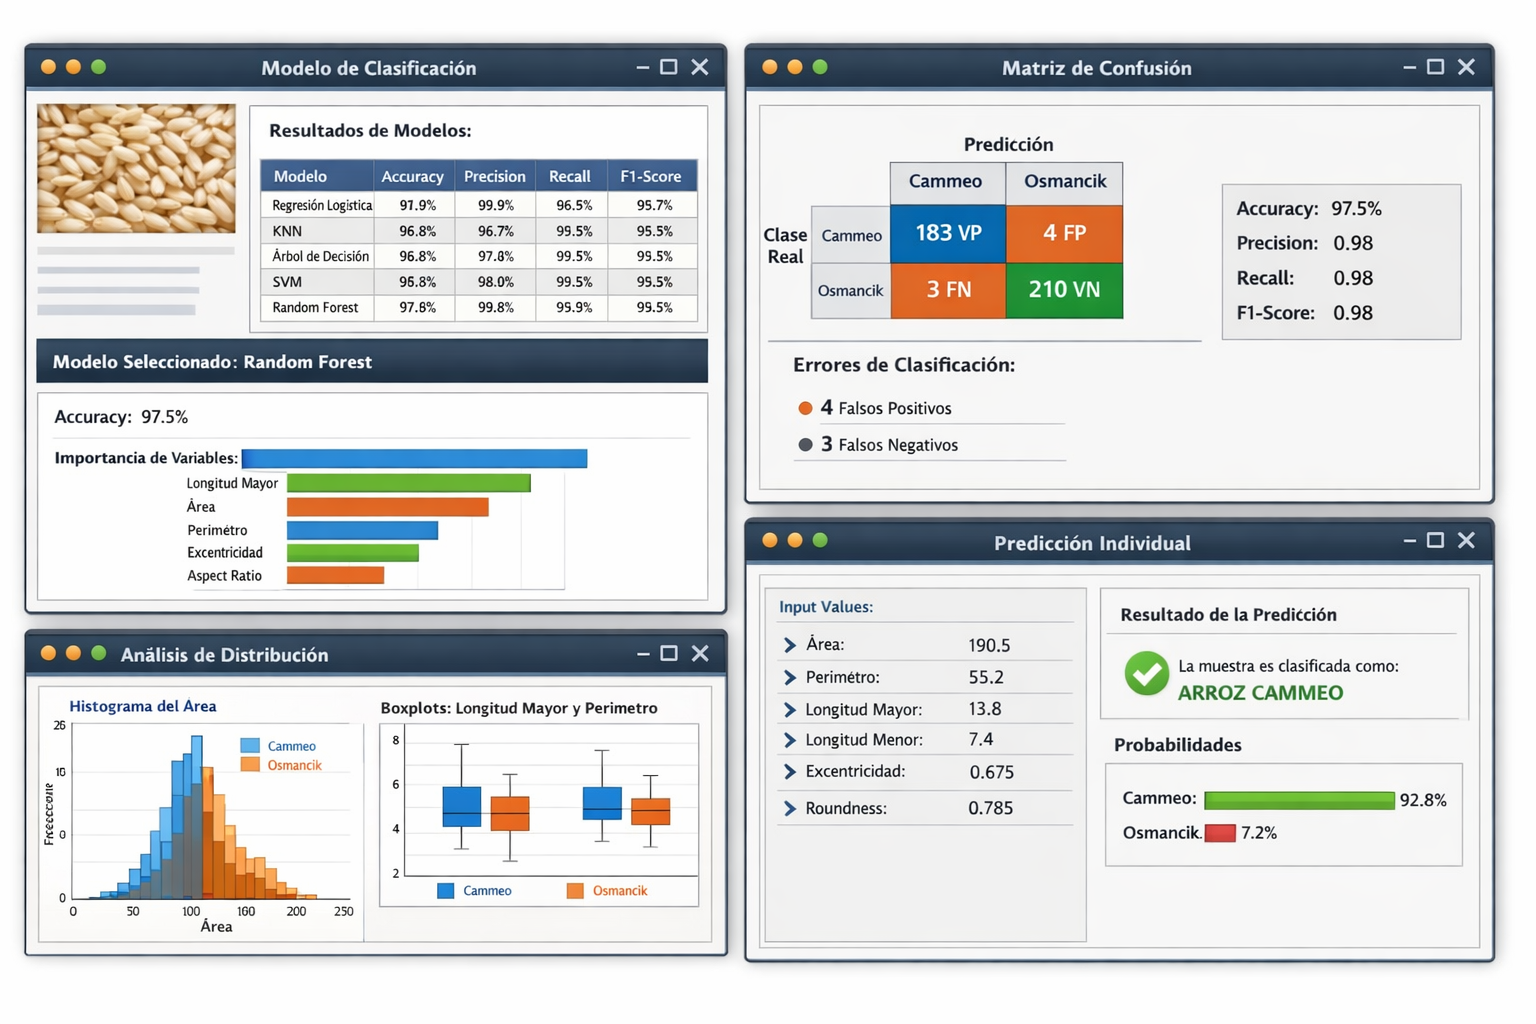